# EDA dan Preprocessing Dataset Titanic

Notebook ini berisi alur lengkap **Exploratory Data Analysis (EDA)** dan **preprocessing** untuk dataset `train.csv` dari Kaggle Titanic.

**Cara menjalankan:**
1. Letakkan `train.csv` di folder yang sama dengan notebook ini.
2. Install library jika belum ada: `pip install pandas numpy matplotlib seaborn scikit-learn`
3. Jalankan sel dari atas ke bawah (Run All).

**Daftar isi**
1. Import library
2. Memuat data dan memahami struktur
3. Analisis univariat (numerik: Age, Fare; kategorikal: Pclass, Sex)
4. Analisis missing values
5. Analisis bivariat terhadap Survived
6. Analisis multivariat
7. Rangkuman insight
8. Preprocessing (missing values, encoding, standardisasi)

## 1. Import library

**Tujuan:** menyiapkan alat yang dipakai di seluruh notebook.

- `pandas` untuk mengolah tabel data (DataFrame).
- `numpy` untuk perhitungan angka.
- `matplotlib` dan `seaborn` untuk membuat grafik.
- `sklearn.preprocessing.StandardScaler` untuk standardisasi di tahap preprocessing.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler


## 2. Memuat data dan memahami struktur

**Tujuan:** memastikan data terbaca dengan benar, mengetahui ukurannya, tipe datanya, dan contoh isinya.

- `shape` = atribut (tanpa tanda kurung) berisi (jumlah baris, jumlah kolom).
- `head()`, `info()`, `describe()` = fungsi (pakai tanda kurung).

**Insight:** data berisi 891 penumpang dan 12 kolom. `Age` (714 nilai), `Cabin` (204), dan `Embarked` (889) memiliki nilai kosong. `Survived` adalah target, bukan fitur.

In [2]:
df = pd.read_csv("train.csv")

# Atribut: ukuran tabel (baris, kolom)
print("Ukuran data:", df.shape)

# Fungsi: 5 baris pertama
df.head()

Ukuran data: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
# Fungsi: ringkasan kolom, jumlah nilai tidak kosong, dan tipe data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [4]:
# Atribut: tipe data setiap kolom
print(df.dtypes)

# Statistik deskriptif untuk kolom numerik
df.describe()

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## 3. Analisis univariat

Univariat berarti meneliti **satu fitur pada satu waktu**.

### 3a. Fitur numerik: Age dan Fare

**Tujuan:** melihat pusat, sebaran, bentuk distribusi, dan outlier.

**Cara membaca:**
- **mean vs median:** jika jauh berbeda, distribusi kemungkinan miring atau ada outlier.
- **skew:** mendekati 0 berarti simetris. Positif besar berarti ekor panjang ke kanan.
- **Box plot:** kotak = 50% data tengah, garis dalam kotak = median, titik di luar whisker = outlier menurut aturan IQR.

In [5]:
# Statistik ringkas untuk Age dan Fare
print(df[["Age", "Fare"]].describe())

# Skewness: ukuran kemiringan distribusi
print("Skew Age :", round(df["Age"].skew(), 3))
print("Skew Fare:", round(df["Fare"].skew(), 3))

              Age        Fare
count  714.000000  891.000000
mean    29.699118   32.204208
std     14.526497   49.693429
min      0.420000    0.000000
25%     20.125000    7.910400
50%     28.000000   14.454200
75%     38.000000   31.000000
max     80.000000  512.329200
Skew Age : 0.389
Skew Fare: 4.787


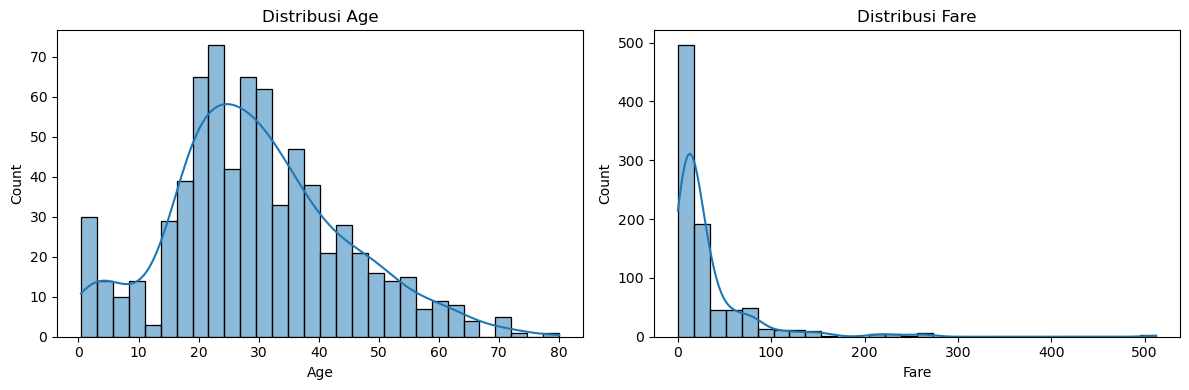

In [6]:
# Histogram berdampingan
# dropna() membuang nilai kosong agar grafik hanya membaca angka
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["Age"].dropna(), bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribusi Age")

sns.histplot(df["Fare"], bins=30, kde=True, ax=axes[1])
axes[1].set_title("Distribusi Fare")

plt.tight_layout()
plt.show()

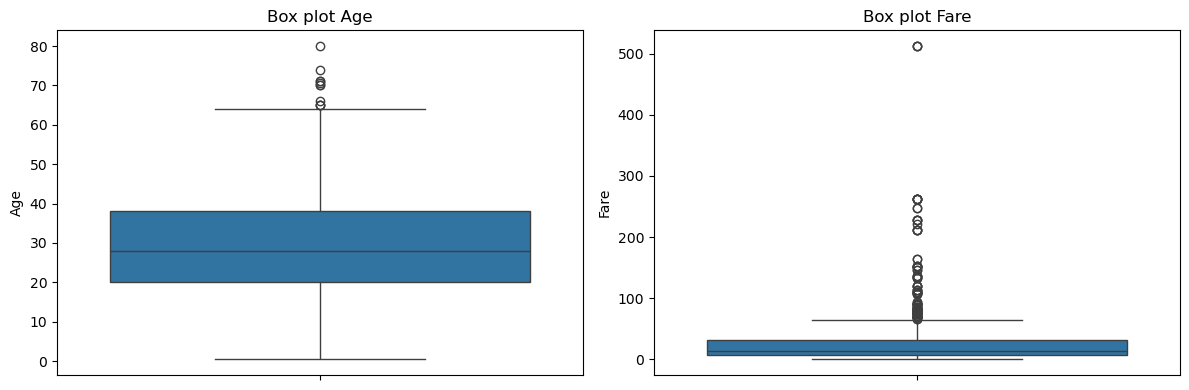

In [7]:
# Box plot berdampingan
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(y=df["Age"].dropna(), ax=axes[0])
axes[0].set_title("Box plot Age")

sns.boxplot(y=df["Fare"], ax=axes[1])
axes[1].set_title("Box plot Fare")

plt.tight_layout()
plt.show()

**Insight Age:**
- mean dan median berdekatan, sehingga distribusinya cukup simetris.
- skew mendekati 0, konfirmasi kesimetrisan. Simetris belum tentu normal, dan bentuk normal perlu dicek dengan cara lain (misalnya Q-Q plot).
- Nilai maksimum (80) jauh di atas kuartil ke-3, sehingga secara statistik termasuk outlier. Nilainya masih valid, jadi tidak dibuang.

**Insight Fare:**
- mean lebih besar dari median, artinya sebagian kecil tiket mahal menarik rata-rata ke atas.
- skew positif besar (sekitar 4,7), distribusi menceng ke kanan dengan ekor panjang.
- Banyak nilai berada di atas batas IQR. Ini mencerminkan tiket kelas 1 dan 2 yang memang jauh lebih mahal.

**Alasan memilih Age dan Fare:** keduanya numerik kontinu dengan rentang lebar, sehingga cocok untuk histogram, box plot, dan statistik ringkas. Fitur numerik lain (`SibSp`, `Parch`) bersifat diskrit dan dianalisis dengan frekuensi.

In [8]:
# Batas IQR untuk Fare
q1 = df["Fare"].quantile(0.25)
q3 = df["Fare"].quantile(0.75)
iqr = q3 - q1

batas_bawah = q1 - 1.5 * iqr
batas_atas = q3 + 1.5 * iqr

jumlah_outlier = (df["Fare"] > batas_atas).sum()
print("Batas atas:", round(batas_atas, 2))
print("Jumlah outlier Fare:", jumlah_outlier)
print(f"Persentase: {jumlah_outlier / len(df) * 100:.1f}%")

Batas atas: 65.63
Jumlah outlier Fare: 116
Persentase: 13.0%


**Insight outlier Fare:** sekitar 63% penumpang berada di atas batas IQR. Jumlah ini terlalu besar untuk disebut "outlier" dalam arti nilai langka. Karena nilainya valid, `Fare` tidak dibuang. Aturan IQR cenderung menandai terlalu banyak titik pada data yang sangat menceng.

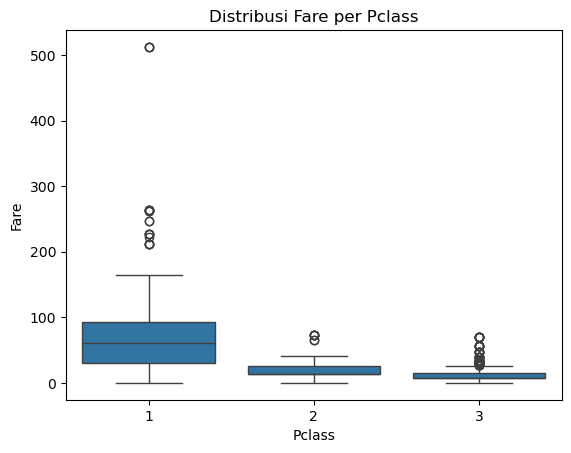

In [9]:
# Distribusi Fare per Pclass, untuk melihat apakah outlier berasal dari kelas tertentu
sns.boxplot(x="Pclass", y="Fare", data=df)
plt.title("Distribusi Fare per Pclass")
plt.show()

**Cara membaca:** jika kotak tiap kelas berada di ketinggian berbeda, `Pclass` dan `Fare` memang berhubungan. Jika kotak kelas 1 masih memanjang jauh ke atas, `Fare` juga bervariasi di dalam kelas 1, sehingga `Fare` membawa informasi tambahan yang tidak ditangkap `Pclass`.

### 3b. Fitur kategorikal: Pclass dan Sex

**Tujuan:** melihat komposisi tiap kategori. `Pclass` berisi angka, tetapi itu **kategori**, bukan jumlah, sehingga rata-ratanya tidak bermakna.

Pclass
1    216
2    184
3    491
Name: count, dtype: int64
Pclass
1    24.2
2    20.7
3    55.1
Name: proportion, dtype: float64


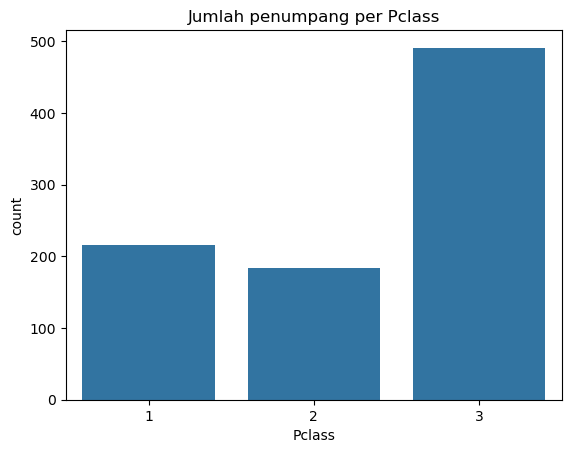

In [10]:
# Jumlah dan persentase penumpang per kelas
print(df["Pclass"].value_counts().sort_index())
print((df["Pclass"].value_counts(normalize=True).sort_index() * 100).round(1))

sns.countplot(x="Pclass", data=df)
plt.title("Jumlah penumpang per Pclass")
plt.show()

Sex
male      577
female    314
Name: count, dtype: int64
Sex
male      64.8
female    35.2
Name: proportion, dtype: float64


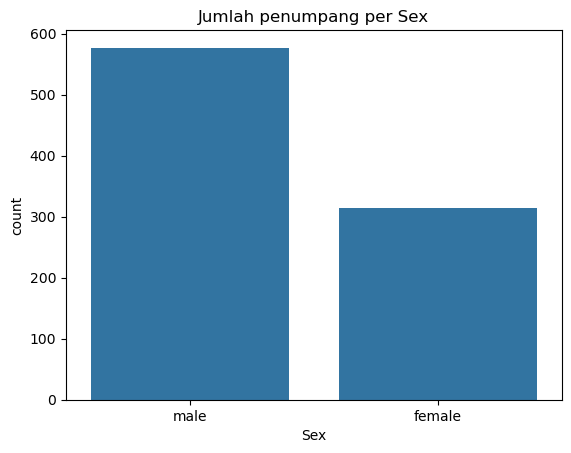

In [11]:
# Jumlah dan persentase penumpang per jenis kelamin
print(df["Sex"].value_counts())
print((df["Sex"].value_counts(normalize=True) * 100).round(1))

sns.countplot(x="Sex", data=df)
plt.title("Jumlah penumpang per Sex")
plt.show()

**Insight:**
- Kelas 3 adalah kelompok terbesar, sekitar 55% penumpang. Kelas 1 sekitar 24%, kelas 2 sekitar 21%.
- Penumpang pria sekitar 65%, wanita sekitar 35%.
- Komposisi ini penting: angka survival keseluruhan akan dipengaruhi kondisi kelompok terbesar.

## 4. Analisis missing values

**Tujuan:** mengetahui kolom mana yang kosong, berapa persen, dan apakah kekosongannya acak.

In [12]:
# Persentase missing values per kolom, dari yang paling banyak kosong
persen_kosong = (df.isnull().mean() * 100).round(1).sort_values(ascending=False)
print(persen_kosong)

Cabin          77.1
Age            19.9
Embarked        0.2
PassengerId     0.0
Survived        0.0
Pclass          0.0
Name            0.0
Sex             0.0
SibSp           0.0
Parch           0.0
Ticket          0.0
Fare            0.0
dtype: float64


In [13]:
# Persentase penumpang yang Cabin-nya terisi, per kelas
# notnull().mean() menghasilkan proporsi True (terisi), dikali 100 jadi persen
print((df.groupby("Pclass")["Cabin"].apply(lambda x: x.notnull().mean()) * 100).round(1))

Pclass
1    81.5
2     8.7
3     2.4
Name: Cabin, dtype: float64


**Insight:**
- `Cabin` kosong sekitar 77%. Angka ini terlalu besar untuk diisi dengan median atau mean, karena nilainya berupa teks seperti `C85`.
- Kekosongan `Cabin` **tidak acak**. Pada kelas 1 sekitar 81% penumpang punya data kabin, sedangkan pada kelas 2 dan 3 hanya sekitar 9% dan 2%. Artinya kekosongan ini membawa informasi tentang kelas.
- `Age` kosong sekitar 20% (177 baris). Terlalu banyak untuk dibuang, sehingga perlu diisi.
- `Embarked` kosong hanya 2 baris, sehingga aman diisi.

## 5. Analisis bivariat terhadap Survived

**Tujuan:** membandingkan setiap fitur dengan target `Survived`. Survival rate = rata-rata kolom `Survived` (0 atau 1) per kelompok, yang sama dengan persentase yang selamat.

### 5a. Sex terhadap Survived

Sex
female    74.2
male      18.9
Name: Survived, dtype: float64


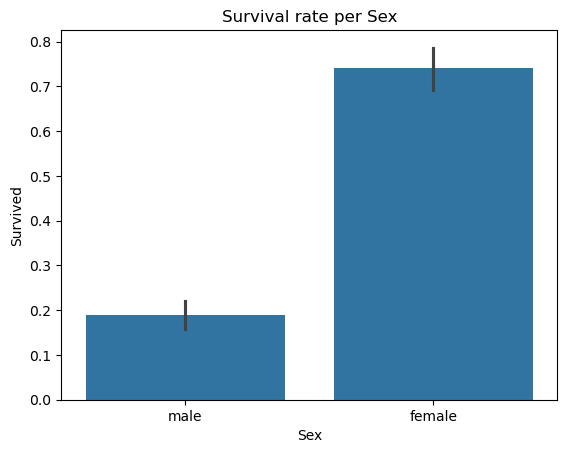

In [14]:
# Survival rate per jenis kelamin (dalam persen)
print((df.groupby("Sex")["Survived"].mean() * 100).round(1))

sns.barplot(x="Sex", y="Survived", data=df)
plt.title("Survival rate per Sex")
plt.show()

**Insight:** survival rate wanita sekitar 74% dan pria sekitar 19%, selisih sekitar 55 poin. `Sex` menjadi fitur yang sangat kuat hubungannya dengan `Survived`.

### 5b. Pclass terhadap Survived

Pclass
1    63.0
2    47.3
3    24.2
Name: Survived, dtype: float64


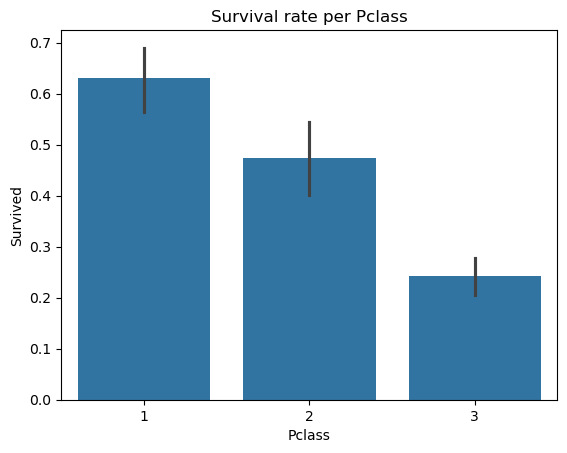

In [15]:
# Survival rate per kelas
print((df.groupby("Pclass")["Survived"].mean() * 100).round(1))

sns.barplot(x="Pclass", y="Survived", data=df)
plt.title("Survival rate per Pclass")
plt.show()

**Insight:** kelas 1 sekitar 63%, kelas 2 sekitar 47%, kelas 3 sekitar 24%. Semakin kecil angka `Pclass` (kelas makin tinggi), semakin besar survival rate. Selisih kelas 1 dan kelas 3 sekitar 39 poin, lebih kecil dari selisih `Sex`.

### 5c. Interaksi Sex dan Pclass

**Tujuan:** memastikan pengaruh `Sex` tetap ada di setiap kelas, dan pengaruh `Pclass` tetap ada di setiap jenis kelamin. Ini mengecek kemungkinan **confounding**.

Sex     female  male
Pclass              
1         96.8  36.9
2         92.1  15.7
3         50.0  13.5
Sex     female  male
Pclass              
1           94   122
2           76   108
3          144   347


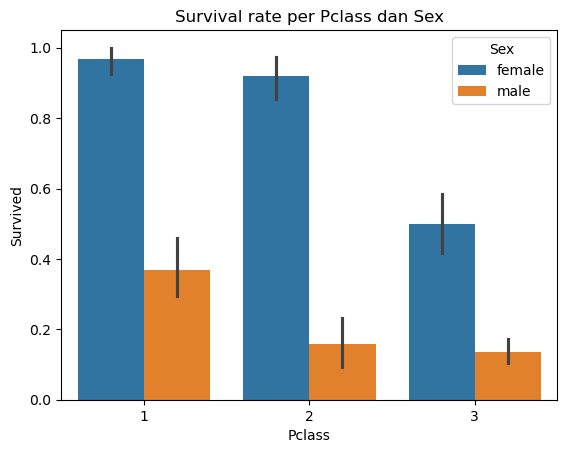

In [16]:
# Tabel silang: baris = Pclass, kolom = Sex, isi = survival rate (%)
tabel_silang = pd.pivot_table(df, values="Survived", index="Pclass", columns="Sex", aggfunc="mean") * 100
print(tabel_silang.round(1))

# Jumlah penumpang per sel, untuk melihat seberapa besar sampel tiap kelompok
print(pd.crosstab(df["Pclass"], df["Sex"]))

sns.barplot(x="Pclass", y="Survived", hue="Sex", data=df)
plt.title("Survival rate per Pclass dan Sex")
plt.show()

**Insight:**
- Di setiap kelas, wanita selamat jauh lebih banyak daripada pria: kelas 1 (96,8% vs 36,9%), kelas 2 (92,1% vs 15,7%), kelas 3 (50% vs 13,5%).
- Jadi `Sex` tetap kuat setelah kelas diperhitungkan, dan bukan sekadar bayangan dari `Pclass`.
- Selisih antarjenis kelamin tidak sama besar di setiap kelas. Ini tanda adanya **interaksi**.
- Pria kelas 1 (36,9%) masih lebih rendah daripada wanita kelas 3 (50%), sehingga jenis kelamin tampak memberi pengaruh lebih besar daripada kelas.

### 5d. Cabin dan Age kosong terhadap Survived

In [17]:
# Apakah punya data Cabin berkaitan dengan survival?
df["punya_cabin"] = df["Cabin"].notnull().astype(int)
print((df.groupby("punya_cabin")["Survived"].mean() * 100).round(1))

# Apakah penumpang dengan Age kosong berbeda dari yang lain?
df["age_kosong"] = df["Age"].isnull().astype(int)
print((df.groupby("age_kosong")["Survived"].mean() * 100).round(1))

# Komposisi kelas (persen per baris) untuk Age terisi (0) dan kosong (1)
print((pd.crosstab(df["age_kosong"], df["Pclass"], normalize="index") * 100).round(1))

punya_cabin
0    30.0
1    66.7
Name: Survived, dtype: float64
age_kosong
0    40.6
1    29.4
Name: Survived, dtype: float64
Pclass         1     2     3
age_kosong                  
0           26.1  24.2  49.7
1           16.9   6.2  76.8


**Cara membaca:** jika survival rate berbeda jauh antara punya dan tidak punya `Cabin`, itu sinyal. Tetapi sinyal ini mungkin hanya bayangan dari `Pclass`, karena penumpang kelas 1 lebih sering punya data kabin. Perlu dicek kembali setelah dibandingkan per kelas.

### 5e. Age terhadap Survived

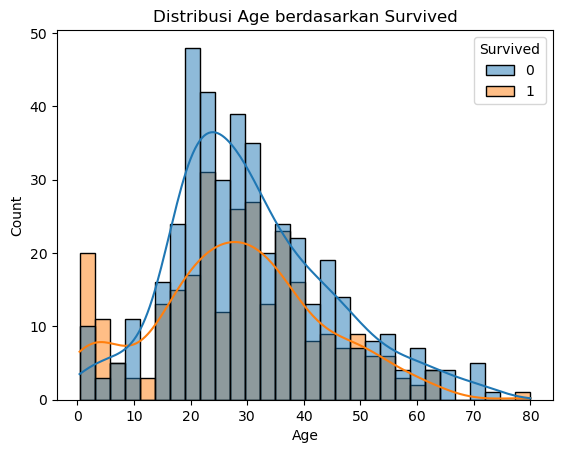

In [18]:
# Distribusi Age untuk yang tidak selamat (0) dan selamat (1)
# astype(str) membuat Survived dibaca sebagai kategori, bukan skala warna
sns.histplot(data=df, x="Age", hue=df["Survived"].astype(str), kde=True, bins=30)
plt.title("Distribusi Age berdasarkan Survived")
plt.show()

**Insight (perlu dicek dengan outputmu):** lihat apakah kelompok usia sangat muda (anak-anak) memiliki bagian selamat yang lebih besar, dan apakah kelompok dewasa muda dominan di kelompok tidak selamat.

### 5f. SibSp, Parch, dan Embarked terhadap Survived

In [19]:
# Survival rate dan jumlah penumpang per kategori
for kolom in ["SibSp", "Parch", "Embarked"]:
    tabel = df.groupby(kolom)["Survived"].agg(survival_rate="mean", jumlah="count")
    tabel["survival_rate"] = (tabel["survival_rate"] * 100).round(1)
    print(f"--- {kolom} ---")
    print(tabel)
    print()

--- SibSp ---
       survival_rate  jumlah
SibSp                       
0               34.5     608
1               53.6     209
2               46.4      28
3               25.0      16
4               16.7      18
5                0.0       5
8                0.0       7

--- Parch ---
       survival_rate  jumlah
Parch                       
0               34.4     678
1               55.1     118
2               50.0      80
3               60.0       5
4                0.0       4
5               20.0       5
6                0.0       1

--- Embarked ---
          survival_rate  jumlah
Embarked                       
C                  55.4     168
Q                  39.0      77
S                  33.7     644



**Insight (perlu dicek dengan outputmu):**
- `SibSp` dan `Parch` menggambarkan ukuran keluarga. Perhatikan apakah penumpang yang sendirian atau keluarga yang sangat besar punya survival rate lebih rendah dibanding keluarga kecil.
- `Embarked` mungkin terlihat berpengaruh, tetapi bisa jadi karena komposisi kelas di tiap pelabuhan, bukan pelabuhannya sendiri. Ini perlu diuji dengan melihat per `Pclass`.

## 6. Analisis multivariat

**Tujuan:** melihat hubungan lebih dari dua fitur sekaligus.

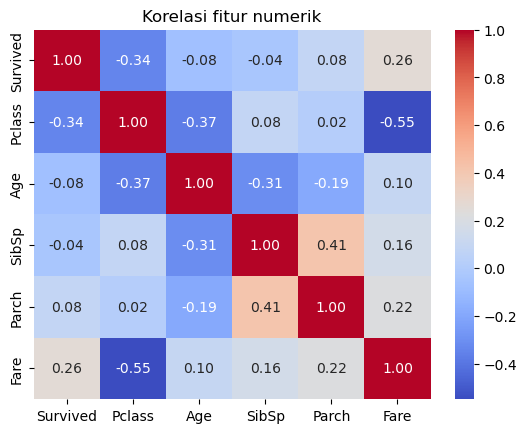

In [20]:
# Heatmap korelasi fitur numerik
# Sex dan Embarked belum numerik, jadi tidak ikut
kolom_num = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
sns.heatmap(df[kolom_num].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Korelasi fitur numerik")
plt.show()

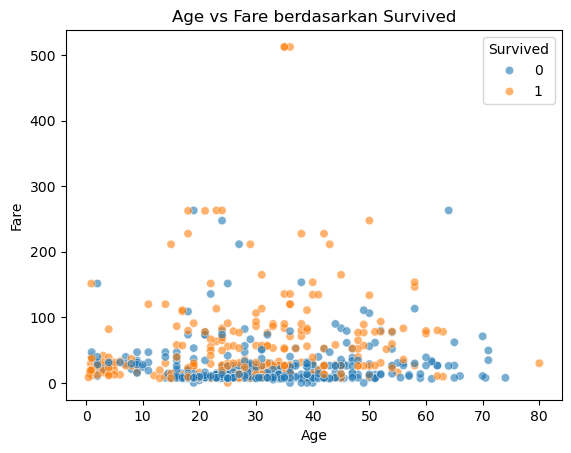

In [21]:
# Scatter Age vs Fare, warna berdasarkan Survived
sns.scatterplot(data=df, x="Age", y="Fare", hue=df["Survived"].astype(str), alpha=0.6)
plt.title("Age vs Fare berdasarkan Survived")
plt.show()

**Cara membaca:**
- Korelasi berkisar -1 sampai 1. Nilai mendekati 0 berarti hampir tidak ada hubungan linear.
- Korelasi hanya menangkap hubungan linear dan hanya untuk angka.
- **Insight (perlu dicek):** `Pclass` dan `Fare` seharusnya berkorelasi negatif (kelas angka kecil, tiket mahal). `Survived` seharusnya berkorelasi negatif terkuat dengan `Pclass` dan positif dengan `Fare`. Korelasi `Age` dengan `Survived` kemungkinan lemah.
- Pada scatter, tiket murah cenderung didominasi kelas 3 dengan survival rendah.

## 7. Rangkuman insight

1. **Sex adalah fitur paling kuat.** Survival rate wanita sekitar 74% dan pria sekitar 19%.
2. **Pclass juga berpengaruh, tetapi lebih lemah dari Sex.** Survival rate kelas 1 sekitar 63%, kelas 2 sekitar 47%, kelas 3 sekitar 24%.
3. **Pengaruh Sex tetap ada di setiap kelas.** Ini bukan sekadar efek dari kelas.
4. **Pengaruh Pclass tetap ada di setiap jenis kelamin.** Wanita kelas 3 (50%) lebih rendah dari wanita kelas 1 (96,8%).
5. **Fare sangat menceng ke kanan** dan banyak nilainya di atas batas IQR. Nilainya valid, sehingga dipertahankan dan distandardisasi.
6. **Cabin kosong sekitar 77%, dan kekosongannya bergantung pada kelas.** Karena itu dibuat fitur `punya_cabin`, bukan langsung dihapus.
7. **Age kosong sekitar 20%.** Usia berbeda menurut kelas dan jenis kelamin, sehingga pengisian per kelompok lebih masuk akal.

**Pertanyaan lanjutan untuk analisis berikutnya:**
- Apakah `Age` berpengaruh setelah `Sex` dan `Pclass` diperhitungkan?
- Apakah ukuran keluarga (`SibSp` + `Parch`) memberi informasi tambahan?

## 8. Preprocessing

Preprocessing dilakukan pada salinan `df_prep` agar `df` tetap berisi data asli untuk EDA.

### 8a. Menangani missing values

- **Embarked** (2 baris kosong): diisi **modus** (nilai paling sering muncul). Aman karena jumlahnya sangat kecil.
- **Age** (sekitar 20% kosong): diisi **median per kelompok Pclass dan Sex**. Median tidak terpengaruh outlier, dan usia berbeda menurut kelompok.
- **Cabin** (sekitar 77% kosong): diubah menjadi fitur `punya_cabin` (1 atau 0), lalu kolom teksnya dibuang.

In [22]:
df_prep = df.copy()

# Embarked: isi dengan modus
df_prep["Embarked"] = df_prep["Embarked"].fillna(df_prep["Embarked"].mode()[0])

# Age: isi dengan median per kelompok Pclass dan Sex
df_prep["Age"] = df_prep.groupby(["Pclass", "Sex"])["Age"].transform(lambda x: x.fillna(x.median()))

# Cabin: fitur punya_cabin sudah dibuat di EDA, kolom teksnya dibuang
df_prep = df_prep.drop(columns=["Cabin"])

# age_kosong hanya dipakai untuk analisis, tidak dibawa ke tahap model
df_prep = df_prep.drop(columns=["age_kosong"])

print("Missing values setelah penanganan:")
print(df_prep.isnull().sum())

Missing values setelah penanganan:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
punya_cabin    0
dtype: int64


### 8b. Membuang kolom yang tidak dipakai sebagai fitur

- **PassengerId**: hanya nomor urut, tidak membawa informasi.
- **Name** dan **Ticket**: berisi teks yang butuh rekayasa fitur tersendiri, di luar cakupan EDA ini.

In [23]:
df_prep = df_prep.drop(columns=["PassengerId", "Name", "Ticket"])
print(df_prep.columns.tolist())

['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'punya_cabin']


### 8c. Encoding fitur kategorikal

- **Sex** adalah kategori biner, cukup diwakili 0 dan 1.
- **Embarked** punya 3 kategori tanpa urutan (C, Q, S). Jika diberi angka 1, 2, 3, model bisa mengira S "lebih besar" dari C. Karena itu dipakai **one-hot encoding**. `drop_first=True` membuang satu kolom agar tidak redundan.

In [24]:
# Sex: female = 1, male = 0
df_prep["Sex"] = df_prep["Sex"].map({"male": 0, "female": 1})

# Embarked: one-hot encoding
df_prep = pd.get_dummies(df_prep, columns=["Embarked"], drop_first=True, dtype=int)

print(df_prep.head())

   Survived  Pclass  Sex   Age  SibSp  Parch     Fare  punya_cabin  \
0         0       3    0  22.0      1      0   7.2500            0   
1         1       1    1  38.0      1      0  71.2833            1   
2         1       3    1  26.0      0      0   7.9250            0   
3         1       1    1  35.0      1      0  53.1000            1   
4         0       3    0  35.0      0      0   8.0500            0   

   Embarked_Q  Embarked_S  
0           0           1  
1           0           0  
2           0           1  
3           0           1  
4           0           1  


### 8d. Standardisasi fitur numerik

**Standardisasi** mengubah setiap nilai menjadi:

**nilai baru = (nilai − rata-rata) ÷ simpangan baku**

Hasilnya, rata-rata sekitar 0 dan simpangan baku sekitar 1. Ini membuat `Age` dan `Fare` sebanding, yang penting untuk model berbasis jarak atau gradien seperti regresi logistik dan KNN.

Catatan: standardisasi tidak mengubah bentuk distribusi. Jadi `Fare` tetap menceng ke kanan. Untuk itu bisa dipakai transformasi logaritma, misalnya `np.log1p`, sebagai pengembangan lanjutan.

In [25]:
# Sebelum standardisasi
print("Sebelum:")
print(df_prep[["Age", "Fare"]].agg(["mean", "std"]).round(3))

# fit_transform: mempelajari rata-rata dan simpangan baku, lalu mengubah nilainya
scaler = StandardScaler()
df_prep[["Age", "Fare"]] = scaler.fit_transform(df_prep[["Age", "Fare"]])

# Sesudah standardisasi
print("Sesudah:")
print(df_prep[["Age", "Fare"]].agg(["mean", "std"]).round(3))
print(df_prep[["Age", "Fare"]].head())

Sebelum:
         Age    Fare
mean  29.112  32.204
std   13.304  49.693
Sesudah:
        Age   Fare
mean  0.000  0.000
std   1.001  1.001
        Age      Fare
0 -0.534891 -0.502445
1  0.668392  0.786845
2 -0.234070 -0.488854
3  0.442776  0.420730
4  0.442776 -0.486337


**Catatan:** `std` dari pandas memakai pembagi n−1, sedangkan `StandardScaler` memakai n, sehingga `std` hasil pandas bisa sedikit berbeda dari 1.

### 8e. Pemeriksaan hasil akhir

In [26]:
print("Ukuran akhir:", df_prep.shape)
print(df_prep.dtypes)
print("Total missing values:", df_prep.isnull().sum().sum())
df_prep.head()

Ukuran akhir: (891, 10)
Survived         int64
Pclass           int64
Sex              int64
Age            float64
SibSp            int64
Parch            int64
Fare           float64
punya_cabin      int64
Embarked_Q       int64
Embarked_S       int64
dtype: object
Total missing values: 0


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,punya_cabin,Embarked_Q,Embarked_S
0,0,3,0,-0.534891,1,0,-0.502445,0,0,1
1,1,1,1,0.668392,1,0,0.786845,1,0,0
2,1,3,1,-0.234070,0,0,-0.488854,0,0,1
3,1,1,1,0.442776,1,0,0.420730,1,0,1
4,0,3,0,0.442776,0,0,-0.486337,0,0,1


**Catatan untuk laporan:**
- Imputasi median dan standardisasi sebaiknya dihitung **hanya dari data training** saat membuat model, agar tidak terjadi kebocoran informasi (*data leakage*). Untuk tugas EDA ini, cukup disebutkan sebagai catatan.
- Kalau ingin menyimpan hasil preprocessing:

In [27]:
df_prep.to_csv("train_preprocessed.csv", index=False)
print("Tersimpan: train_preprocessed.csv")

Tersimpan: train_preprocessed.csv
